# 03 · Logística e SLA

**Pergunta:** a operação entrega no prazo? Onde estão os gargalos (etapas, regiões, rotas) e quanto o atraso custa em satisfação?

Base: pedidos entregues de jan/2017 a ago/2018. **Atraso** = entrega em dia posterior à data prometida ao cliente.

## Principais conclusões

- **A entrega leva 12,5 dias em média** (mediana de 10,2) contra 23,6 prometidos, e 6,8% dos pedidos chegam atrasados.
- **O transporte é o gargalo:** responde por 74% do prazo. Quando o vendedor posta depois do limite, o atraso sobe de 5,4% para 21%, mas 72% dos atrasos acontecem mesmo com a postagem no prazo.
- **O atraso dispara nos picos de demanda:** 19% em mar/2018, 14% em fev/2018 e 12% em nov/2017 (Black Friday).
- **Desigualdade regional:** SP recebe em 8,7 dias com 4,5% de atraso; Alagoas espera 24,5 dias com 21,5% de atraso. No Norte, o frete é 26% do valor do pedido, contra 17% no Sudeste.
- **A oferta é concentrada:** 84% dos pedidos saem do Sudeste. Só 4,8% dos pedidos do Nordeste são atendidos por vendedores da região, e nenhum do Norte.
- **O atraso destrói a satisfação:** a nota média cai de 4,29 para 2,27, e de 4 a 7 dias de atraso já levam 68% dos clientes a dar nota 1 ou 2.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from olist import config, data, prep, viz
from olist.viz import CORES, brl, num, pct

viz.aplicar_estilo()

In [2]:
t = data.carregar_todas()
pedidos = prep.carregar_base_pedidos()
entregues = pedidos[pedidos.entregue].copy()

# Data-limite que o vendedor tinha para postar (a mais tardia entre os itens do pedido)
limite = t["order_items"].groupby("order_id").shipping_limit_date.max()
entregues = entregues.join(limite, on="order_id")
entregues["postagem_atrasada"] = entregues.order_delivered_carrier_date > entregues.shipping_limit_date
entregues["folga"] = entregues.dias_prometidos - entregues.dias_entrega

## 1. Panorama

In [3]:
pd.Series({
    "Pedidos entregues": num(len(entregues)),
    "Prazo médio de entrega": f"{num(entregues.dias_entrega.mean(), 1)} dias",
    "Prazo mediano de entrega": f"{num(entregues.dias_entrega.median(), 1)} dias",
    "Prazo médio prometido": f"{num(entregues.dias_prometidos.mean(), 1)} dias",
    "Entregues com atraso": pct(entregues.atrasado.mean()),
    "Entregues 7+ dias antes do prometido": pct((entregues.folga >= 7).mean()),
}).to_frame("valor")

,valor
Pedidos entregues,96.203
Prazo médio de entrega,"12,5 dias"
Prazo mediano de entrega,"10,2 dias"
Prazo médio prometido,"23,6 dias"
Entregues com atraso,"6,8%"
Entregues 7+ dias antes do prometido,"73,9%"


## 2. Onde o tempo é gasto

Decomposição do prazo em três etapas. Etapas com duração negativa (inconsistências da base, cerca de 1,4% dos pedidos) ficam de fora.

In [4]:
etapas = entregues[["dias_aprovacao", "dias_postagem", "dias_transporte"]].where(lambda d: d >= 0)
etapas.columns = ["Aprovação do pagamento", "Preparação e postagem (vendedor)", "Transporte até o cliente"]
resumo = etapas.agg(["mean", "median"]).T.rename(columns={"mean": "média (dias)", "median": "mediana (dias)"})
resumo["% do prazo médio"] = (resumo["média (dias)"] / resumo["média (dias)"].sum()).map(pct)
resumo.round(1)

,média (dias),mediana (dias),% do prazo médio
Aprovação do pagamento,0.40,0.00,"3,4%"
Preparação e postagem (vendedor),2.80,1.80,"22,4%"
Transporte até o cliente,9.30,7.10,"74,2%"


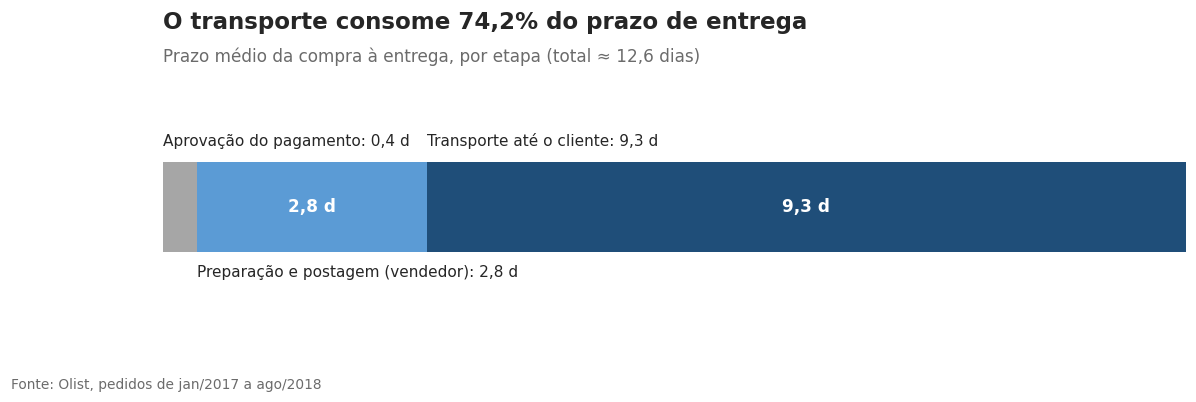

In [5]:
cores = [CORES["neutro"], CORES["secundaria"], CORES["principal"]]
fig, ax = plt.subplots(figsize=(12, 3.2))
inicio = 0
# Rótulos alternam acima/abaixo da barra para não se sobreporem nos segmentos curtos
for i, ((etapa, linha), cor) in enumerate(zip(resumo.iterrows(), cores)):
    largura = linha["média (dias)"]
    ax.barh(0, largura, left=inicio, color=cor, height=0.5)
    if largura > 1.5:
        ax.text(inicio + largura / 2, 0, f"{num(largura, 1)} d", ha="center", va="center", color="white", fontweight="bold")
    y, va = (0.32, "bottom") if i % 2 == 0 else (-0.32, "top")
    ax.text(inicio, y, f"{etapa}: {num(largura, 1)} d", ha="left", va=va, fontsize=10, color=CORES["texto"])
    inicio += largura
ax.set_xlim(0, inicio)
ax.set_ylim(-0.75, 0.75)
ax.axis("off")
viz.titulo(ax, f"O transporte consome {resumo['% do prazo médio'].iloc[2]} do prazo de entrega",
           f"Prazo médio da compra à entrega, por etapa (total ≈ {num(inicio, 1)} dias)")
viz.fonte(fig)
viz.salvar(fig, "03_etapas_prazo")

### Quem atrasa: vendedor ou transporte?

In [6]:
atrasados = entregues[entregues.atrasado == 1]
print(f"Pedidos postados pelo vendedor depois do prazo-limite: {pct(entregues.postagem_atrasada.mean())}")
print(f"Entre os pedidos atrasados, postagem tardia do vendedor: {pct(atrasados.postagem_atrasada.mean())}")
print()
print("Taxa de atraso ao cliente conforme a postagem:")
entregues.groupby("postagem_atrasada").atrasado.agg(taxa_atraso="mean", pedidos="size").assign(taxa_atraso=lambda d: d.taxa_atraso.map(pct)).rename(index={False: "postado no prazo", True: "postado com atraso"})

Pedidos postados pelo vendedor depois do prazo-limite: 8,9%
Entre os pedidos atrasados, postagem tardia do vendedor: 27,7%

Taxa de atraso ao cliente conforme a postagem:


,taxa_atraso,pedidos
postagem_atrasada,,
postado no prazo,"5,4%",87622
postado com atraso,"21,1%",8581


## 3. Prometido vs. realizado

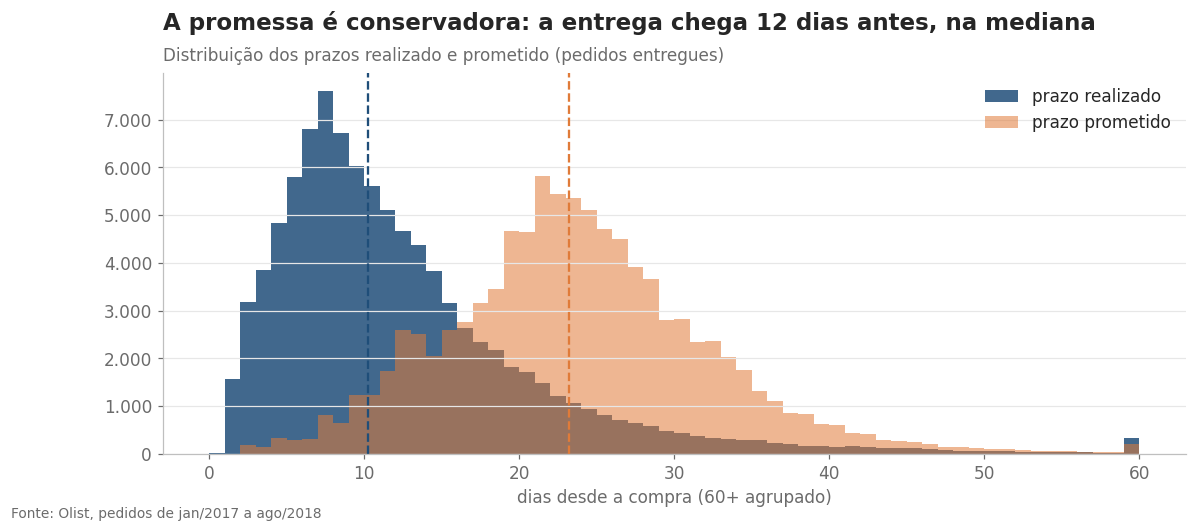

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
faixa = np.arange(0, 61, 1)
ax.hist(entregues.dias_entrega.clip(upper=60), bins=faixa, color=CORES["principal"], alpha=0.85, label="prazo realizado")
ax.hist(entregues.dias_prometidos.clip(upper=60), bins=faixa, color=CORES["destaque"], alpha=0.55, label="prazo prometido")
ax.axvline(entregues.dias_entrega.median(), color=CORES["principal"], ls="--")
ax.axvline(entregues.dias_prometidos.median(), color=CORES["destaque"], ls="--")
ax.set_xlabel("dias desde a compra (60+ agrupado)")
ax.yaxis.set_major_formatter(viz.eixo_num)
ax.legend()
viz.titulo(ax, f"A promessa é conservadora: a entrega chega {num(entregues.folga.median(), 0)} dias antes, na mediana",
           "Distribuição dos prazos realizado e prometido (pedidos entregues)")
viz.fonte(fig)
viz.salvar(fig, "03_prometido_realizado")

A folga na mediana não significa que dá para prometer menos: a distribuição do prazo realizado tem uma **cauda longa** de entregas lentas, e é ela que define o prazo seguro. O notebook 07 mostra que, nos grandes estados, 5% das entregas já levam mais do que a promessa.

## 4. Atraso ao longo do tempo

Meses com maior taxa de atraso:
mes
2018-03-01    19,0%
2018-02-01    14,1%
2017-11-01    12,4%


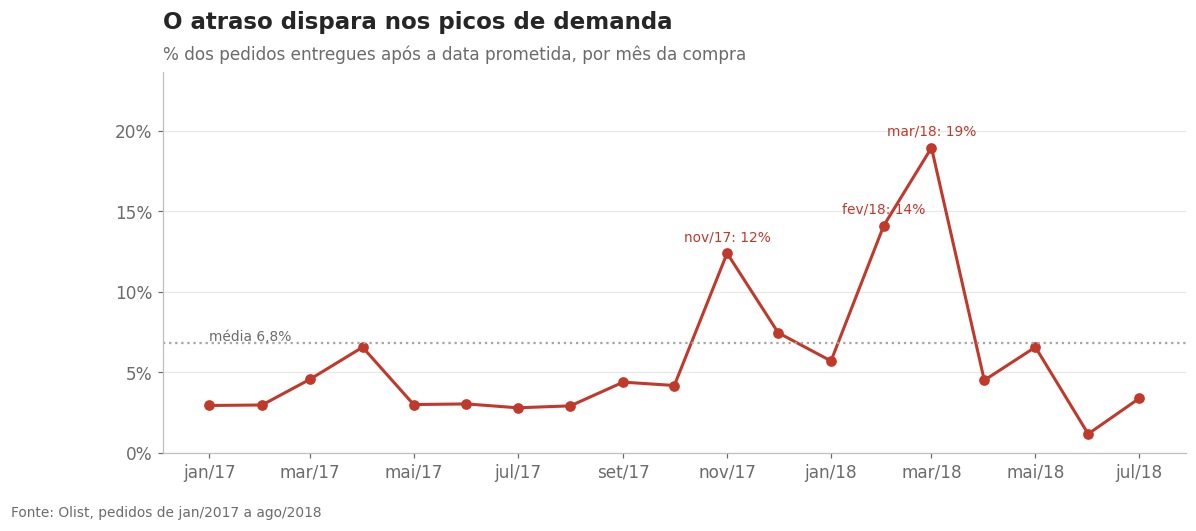

In [8]:
mensal = entregues[prep.no_periodo(entregues.order_purchase_timestamp, config.INICIO_JANELA, config.FIM_MES_COMPLETO)].groupby("mes").agg(
    taxa_atraso=("atrasado", "mean"), prazo=("dias_entrega", "mean"), pedidos=("order_id", "size"))
picos = mensal.taxa_atraso.nlargest(3)
print("Meses com maior taxa de atraso:")
print(picos.map(pct).to_string())

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(mensal.index, mensal.taxa_atraso, color=CORES["negativo"], marker="o", lw=2)
ax.axhline(entregues.atrasado.mean(), color=CORES["neutro"], ls=":")
ax.text(mensal.index[0], entregues.atrasado.mean(), f"média {pct(entregues.atrasado.mean())}", va="bottom", color=CORES["subtexto"], fontsize=9)
for mes, v in picos.items():
    ax.annotate(f"{viz.mes_ano(mes)}: {pct(v, 0)}", (mes, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=CORES["negativo"])
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.xaxis.set_major_formatter(viz.eixo_mes)
ax.set_ylim(0, picos.max() * 1.25)
viz.titulo(ax, "O atraso dispara nos picos de demanda", "% dos pedidos entregues após a data prometida, por mês da compra")
viz.fonte(fig)
viz.salvar(fig, "03_atraso_mensal")

## 5. Desempenho por estado

In [9]:
uf = entregues.groupby("customer_state").agg(
    pedidos=("order_id", "size"), prazo=("dias_entrega", "mean"), atraso=("atrasado", "mean"),
    frete_pct=("perc_frete", "median"), prometido=("dias_prometidos", "mean"))
uf.sort_values("prazo").assign(
    prazo=lambda d: d.prazo.round(1), prometido=lambda d: d.prometido.round(1),
    atraso=lambda d: d.atraso.map(pct), frete_pct=lambda d: d.frete_pct.map(pct))

,pedidos,prazo,atraso,frete_pct,prometido
customer_state,,,,,
SP,40399,8.70,"4,5%","15,8%",19.10
PR,4903,12.00,"4,1%","19,9%",24.50
MG,11319,12.00,"4,6%","19,2%",24.50
DF,2074,12.90,"5,7%","19,5%",24.20
SC,3537,14.90,"8,2%","19,7%",25.70
RS,5327,15.30,"6,1%","20,3%",28.40
RJ,12310,15.30,"12,1%","19,2%",26.30
GO,1950,15.60,"6,6%","20,1%",27.00
MS,701,15.60,"9,7%","19,8%",26.00


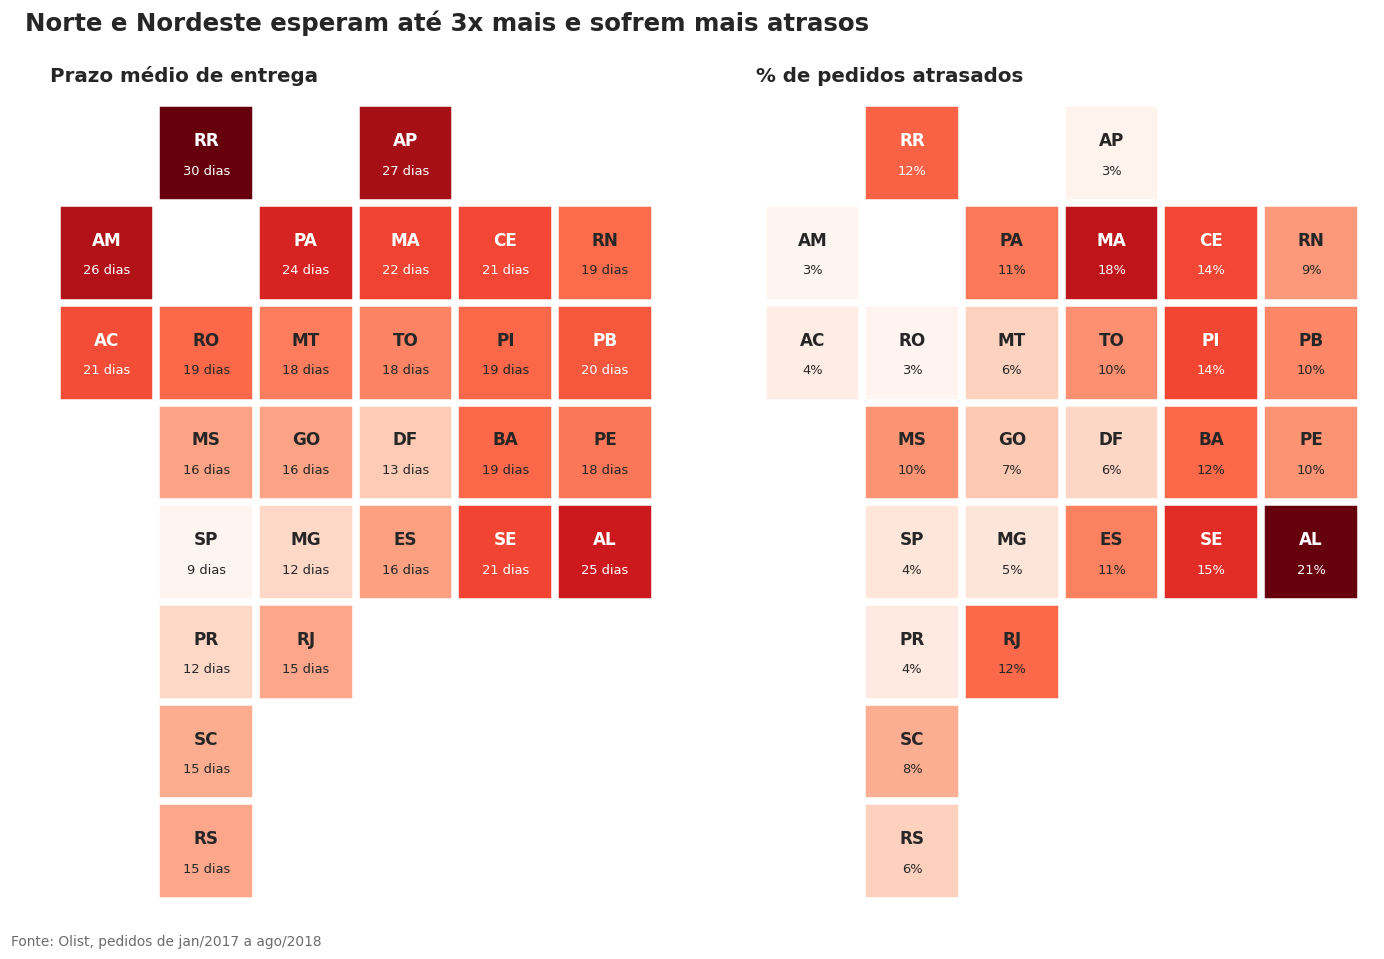

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 8.5))
viz.mapa_uf(uf.prazo, ax=axes[0], cmap="Reds", formato=lambda v: f"{v:.0f} dias")
viz.mapa_uf(uf.atraso, ax=axes[1], cmap="Reds", formato=lambda v: pct(v, 0))
axes[0].set_title("Prazo médio de entrega", fontsize=13, pad=6)
axes[1].set_title("% de pedidos atrasados", fontsize=13, pad=6)
fig.suptitle("Norte e Nordeste esperam até 3x mais e sofrem mais atrasos", x=0.02, ha="left", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
viz.fonte(fig)
viz.salvar(fig, "03_mapa_logistica")

## 6. Rotas: de onde sai e para onde vai

Pedidos que saem do Sudeste: 83,5%


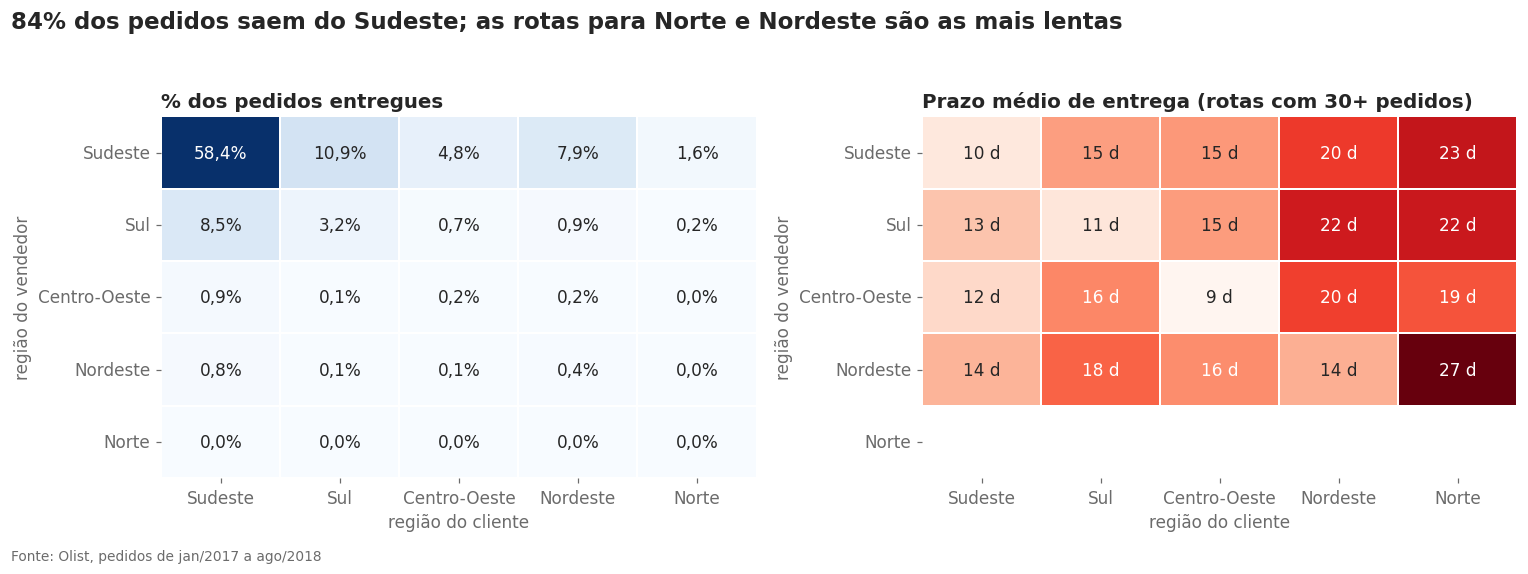

In [11]:
ordem = config.ORDEM_REGIOES
volume = pd.crosstab(entregues.regiao_seller, entregues.regiao, normalize=True).reindex(index=ordem, columns=ordem)
contagem = pd.crosstab(entregues.regiao_seller, entregues.regiao).reindex(index=ordem, columns=ordem).fillna(0)
# Rotas com menos de 30 pedidos ficam em branco: a média não é confiável
prazo_rota = (entregues.pivot_table(index="regiao_seller", columns="regiao", values="dias_entrega", aggfunc="mean")
              .reindex(index=ordem, columns=ordem).where(contagem >= 30))
print(f"Pedidos que saem do Sudeste: {pct(volume.loc['Sudeste'].sum())}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(volume, annot=volume.map(lambda v: pct(v)), fmt="", cmap="Blues", cbar=False, ax=axes[0], linewidths=1, linecolor="white")
sns.heatmap(prazo_rota, annot=prazo_rota.map(lambda v: "" if pd.isna(v) else f"{v:.0f} d"), fmt="", cmap="Reds", cbar=False, ax=axes[1], linewidths=1, linecolor="white")
for ax, nome in zip(axes, ["% dos pedidos entregues", "Prazo médio de entrega (rotas com 30+ pedidos)"]):
    ax.set_xlabel("região do cliente")
    ax.set_ylabel("região do vendedor")
    ax.set_title(nome, fontsize=13, pad=6)
    ax.grid(False)
fig.suptitle(f"{pct(volume.loc['Sudeste'].sum(), 0)} dos pedidos saem do Sudeste; as rotas para Norte e Nordeste são as mais lentas",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
viz.fonte(fig)
viz.salvar(fig, "03_rotas")

In [12]:
entregues["mesma_regiao"] = entregues.regiao == entregues.regiao_seller
local = entregues.groupby("regiao").mesma_regiao.mean().reindex(ordem)
print("Pedidos atendidos por vendedor da própria região:")
print(local.map(pct).to_string())

Pedidos atendidos por vendedor da própria região:
regiao
Sudeste         85,1%
Sul             22,1%
Centro-Oeste     3,7%
Nordeste         4,8%
Norte            0,0%


## 7. Peso do frete

             frete_medio frete_pct  ticket
regiao                                    
Sudeste            R$ 20     17,1%  R$ 150
Sul                R$ 24     20,1%  R$ 162
Centro-Oeste       R$ 26     20,1%  R$ 177
Nordeste           R$ 36     23,9%  R$ 201
Norte              R$ 41     26,3%  R$ 223


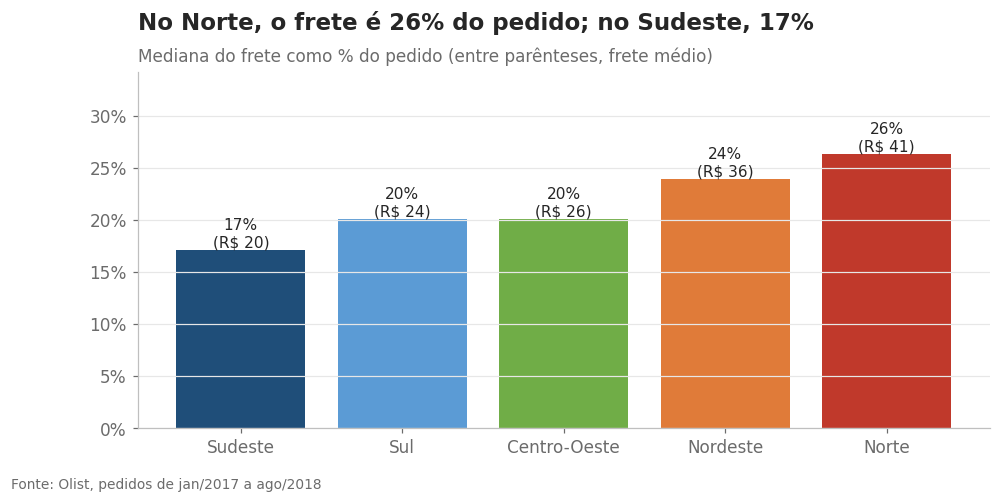

In [13]:
reg = entregues.groupby("regiao").agg(frete_medio=("valor_frete", "mean"), frete_pct=("perc_frete", "median"),
                                      ticket=("gmv", "mean")).reindex(ordem)
print(reg.assign(frete_medio=reg.frete_medio.map(brl), ticket=reg.ticket.map(brl), frete_pct=reg.frete_pct.map(pct)).to_string())

fig, ax = plt.subplots(figsize=(10, 4.2))
barras = ax.bar(reg.index, reg.frete_pct, color=[viz.CORES_REGIAO[r] for r in reg.index])
for barra, v, f in zip(barras, reg.frete_pct, reg.frete_medio):
    ax.text(barra.get_x() + barra.get_width() / 2, v, f"{pct(v, 0)}\n({brl(f)})", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(viz.eixo_pct)
ax.set_ylim(0, reg.frete_pct.max() * 1.3)
viz.titulo(ax, f"No Norte, o frete é {pct(reg.frete_pct['Norte'], 0)} do pedido; no Sudeste, {pct(reg.frete_pct['Sudeste'], 0)}",
           "Mediana do frete como % do pedido (entre parênteses, frete médio)")
viz.fonte(fig)
viz.salvar(fig, "03_frete_regiao")

## 8. Atraso × avaliação do cliente

In [14]:
com_nota = entregues.dropna(subset=["review_score"])
rotulos = ["10+ dias antes", "5–9 dias antes", "1–4 dias antes", "no dia", "1–3 dias depois", "4–7 dias depois", "8–14 dias depois", "15+ dias depois"]
faixas = pd.cut(com_nota.dias_atraso, [-np.inf, -10, -5, -1, 0, 3, 7, 14, np.inf], labels=rotulos)
curva = com_nota.groupby(faixas, observed=True).agg(nota=("review_score", "mean"), nota_baixa=("nota_baixa", "mean"), pedidos=("order_id", "size"))
rho = com_nota[["dias_atraso", "review_score"]].corr(method="spearman").iloc[0, 1]
nota_prazo = com_nota.loc[com_nota.atrasado == 0, "review_score"].mean()
nota_atraso = com_nota.loc[com_nota.atrasado == 1, "review_score"].mean()
print(f"Nota média no prazo: {nota_prazo:.2f} | com atraso: {nota_atraso:.2f} | correlação de Spearman (dias de atraso × nota): {rho:.2f}")
curva.assign(nota=curva.nota.round(2), nota_baixa=curva.nota_baixa.map(pct))

Nota média no prazo: 4.29 | com atraso: 2.27 | correlação de Spearman (dias de atraso × nota): -0.18


,nota,nota_baixa,pedidos
dias_atraso,,,
10+ dias antes,4.32,"8,9%",61270
5–9 dias antes,4.26,"9,6%",20027
1–4 dias antes,4.14,"11,2%",6605
no dia,4.03,"12,4%",1280
1–3 dias depois,3.29,"32,1%",1851
4–7 dias depois,2.10,"67,7%",1748
8–14 dias depois,1.67,"80,2%",1446
15+ dias depois,1.72,"78,3%",1333


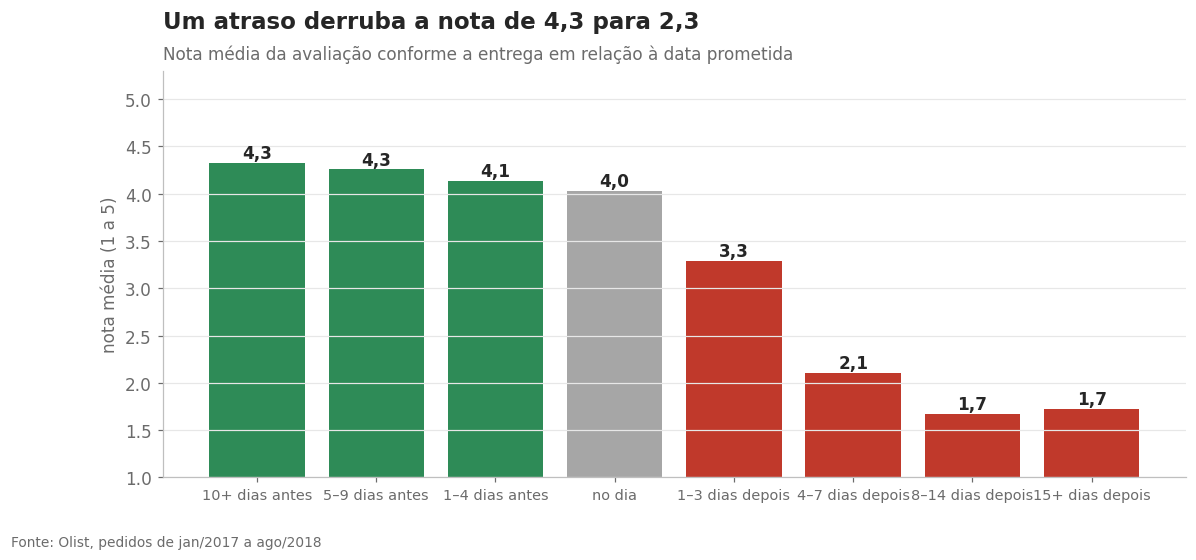

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.8))
cores = [CORES["positivo"]] * 3 + [CORES["neutro"]] + [CORES["negativo"]] * 4
barras = ax.bar(curva.index.astype(str), curva.nota, color=cores)
for barra, v in zip(barras, curva.nota):
    ax.text(barra.get_x() + barra.get_width() / 2, v + 0.05, f"{v:.1f}".replace(".", ","), ha="center", fontweight="bold")
ax.set_ylim(1, 5.3)
ax.set_ylabel("nota média (1 a 5)")
ax.tick_params(axis="x", labelsize=9.5)
viz.titulo(ax, f"Um atraso derruba a nota de {nota_prazo:.1f} para {nota_atraso:.1f}".replace(".", ","),
           "Nota média da avaliação conforme a entrega em relação à data prometida")
viz.fonte(fig)
viz.salvar(fig, "03_atraso_vs_nota")